# Customer Purchase Prediction Using Machine Learning

**AIML Mini-Project**
## Problem Statement
Predict whether a customer who made a valid purchase in the previous 90 days will make at least one valid purchase during the following 30 days.

## Objectives
1. Understand and preprocess a real-world retail transaction dataset.
2. Perform exploratory data analysis (EDA) using tables and visualizations.
3. Engineer customer-level features using historical transactions only.
4. Train and compare classification algorithms.
5. Evaluate the selected model on later, held-out time periods.
6. Interpret important features and save the trained model and results.

**Dataset:** UCI Online Retail, containing transactions from a UK-based online retailer. Source: https://archive.ics.uci.edu/dataset/352/online-retail

> Run the notebook from top to bottom in Google Colab. This notebook is for the **AIML component only**. MongoDB and Streamlit stay in the separate Python application.

### Modelling decisions
- A valid purchase is a non-cancelled invoice row with positive quantity and positive unit price, linked to a known customer and valid timestamp.
- Each monthly snapshot uses the previous 90 days as its feature window and the following 30 days as its target window.
- Features use only transactions before the snapshot. Future transactions are used only to create the target label.
- The latest two complete monthly snapshots are held out for final testing.
- Model and threshold selection use rolling, time-ordered validation.
- The notebook compares models and reports the measured results. Better performance is a goal, not a guaranteed outcome.


## 1. Install dependencies


In [1]:
%pip -q install openpyxl scikit-learn==1.6.1 matplotlib joblib


## 2. Import libraries and connect Google Drive



In [2]:
from pathlib import Path
import json
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from google.colab import drive
drive.mount('/content/drive')

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve
)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
warnings.filterwarnings("default")

# Support the two project-folder spellings used during setup.
candidate_project_dirs = [
    Path('/content/drive/MyDrive/customer_purchase_prediction'),
    Path('/content/drive/MyDrive/customer-purchase-prediction'),
]
PROJECT_DIR = next(
    (path for path in candidate_project_dirs if path.exists()),
    candidate_project_dirs[0]
)

RAW_DIR = PROJECT_DIR / 'data' / 'raw'
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
REPORTS_DIR = PROJECT_DIR / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
MODELS_DIR = PROJECT_DIR / 'models'

for folder in [RAW_DIR, PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

candidate_files = [
    project_dir / 'data' / 'raw' / 'Online Retail.xlsx'
    for project_dir in candidate_project_dirs
]
candidate_files += [
    project_dir / 'Online Retail.xlsx'
    for project_dir in candidate_project_dirs
]
RAW_FILE = next((path for path in candidate_files if path.is_file()), None)

if RAW_FILE is None:
    print("Online Retail.xlsx was not found in the expected Drive folders.")
    print("Upload it to this Colab session or place it in data/raw.")
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("Please upload Online Retail.xlsx to continue.")
    uploaded_name = next(iter(uploaded.keys()))
    RAW_FILE = Path('/content') / uploaded_name

print("Project folder:", PROJECT_DIR)
print("Dataset file:", RAW_FILE)
print("Dataset exists:", RAW_FILE.is_file())
print("scikit-learn version:", __import__('sklearn').__version__)


Mounted at /content/drive
Project folder: /content/drive/MyDrive/customer_purchase_prediction
Dataset file: /content/drive/MyDrive/customer_purchase_prediction/data/raw/Online Retail.xlsx
Dataset exists: True
scikit-learn version: 1.6.1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Load the dataset


In [3]:
raw_df = pd.read_excel(RAW_FILE, engine='openpyxl')
df = raw_df.copy()

print("Dataset loaded successfully.")
print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


Dataset loaded successfully.

First 5 rows:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Last 5 rows:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


## 4. Data Preparation

### 4.1 Find the shape of the dataset


In [4]:
print("Number of rows:", raw_df.shape[0])
print("Number of columns:", raw_df.shape[1])
print("Dataset dimensions:", raw_df.shape)


Number of rows: 541909
Number of columns: 8
Dataset dimensions: (541909, 8)


### 4.2 Check column names and data types


In [5]:
print("Column names:")
print(raw_df.columns.tolist())
print("\nData types:")
display(raw_df.dtypes.rename("Data Type").to_frame())


Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Data Type
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


### 4.3 Print information about the DataFrame


In [6]:
raw_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 4.4 Provide descriptive statistics


In [7]:
print("Numeric column statistics:")
display(raw_df.describe().T)
print("All-column summary:")
display(raw_df.describe(include="all").T)


Numeric column statistics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


All-column summary:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 4.5 Find duplicate records


In [8]:
print("Number of exact duplicate rows:", int(raw_df.duplicated().sum()))


Number of exact duplicate rows: 5268


### 4.6 Check for missing values


In [9]:
missing_summary = raw_df.isna().sum().rename("Missing Values").to_frame()
missing_summary["Missing Percentage"] = (raw_df.isna().mean() * 100).round(2)
display(missing_summary)
print("Total missing cells:", int(raw_df.isna().sum().sum()))


,Missing Values,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Total missing cells: 136534


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 4.7 Inspect unique values and transaction validity


In [10]:
print("Unique values in each column:")
display(raw_df.nunique(dropna=True).rename("Unique Values").to_frame())

cancelled_mask = (
    raw_df["InvoiceNo"].astype(str).str.strip().str.upper().str.startswith("C")
)
quantity_numeric = pd.to_numeric(raw_df["Quantity"], errors="coerce")
price_numeric = pd.to_numeric(raw_df["UnitPrice"], errors="coerce")

print("Rows with cancellation invoice IDs:", int(cancelled_mask.sum()))
print("Rows with Quantity <= 0:", int((quantity_numeric <= 0).sum()))
print("Rows with UnitPrice <= 0:", int((price_numeric <= 0).sum()))
print("Rows missing CustomerID:", int(raw_df["CustomerID"].isna().sum()))
print("First transaction timestamp:", raw_df["InvoiceDate"].min())
print("Last transaction timestamp:", raw_df["InvoiceDate"].max())
print("Unique customers (non-missing):", int(raw_df["CustomerID"].nunique(dropna=True)))


Unique values in each column:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Unique Values
InvoiceNo,25900
StockCode,4070
Description,4223
Quantity,722
InvoiceDate,23260
UnitPrice,1630
CustomerID,4372
Country,38


Rows with cancellation invoice IDs: 9288
Rows with Quantity <= 0: 10624
Rows with UnitPrice <= 0: 2517
Rows missing CustomerID: 135080
First transaction timestamp: 2010-12-01 08:26:00
Last transaction timestamp: 2011-12-09 12:50:00
Unique customers (non-missing): 4372


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Data Preprocessing

### Cleaning decisions

In [11]:
work = raw_df.copy()
work.columns = work.columns.astype(str).str.strip()

required_columns = [
    "InvoiceNo", "StockCode", "Quantity", "InvoiceDate",
    "UnitPrice", "CustomerID", "Country"
]
missing_required = [column for column in required_columns if column not in work.columns]
if missing_required:
    raise ValueError(f"Dataset is missing required columns: {missing_required}")

work["InvoiceNo"] = work["InvoiceNo"].astype(str).str.strip()
work["StockCode"] = work["StockCode"].astype(str).str.strip()
work["InvoiceDate"] = pd.to_datetime(work["InvoiceDate"], errors="coerce")
work["CustomerID"] = pd.to_numeric(work["CustomerID"], errors="coerce")
work["Quantity"] = pd.to_numeric(work["Quantity"], errors="coerce")
work["UnitPrice"] = pd.to_numeric(work["UnitPrice"], errors="coerce")

cleaning_log = [
    {"Step": "Original rows", "Rows remaining": len(work), "Rows excluded at step": 0}
]

def log_filter(step_name, keep_mask):
    global work, cleaning_log
    before = len(work)
    work = work.loc[keep_mask].copy()
    cleaning_log.append({
        "Step": step_name,
        "Rows remaining": len(work),
        "Rows excluded at step": before - len(work),
    })

before = len(work)
work = work.drop_duplicates().copy()
cleaning_log.append({
    "Step": "Remove exact duplicates",
    "Rows remaining": len(work),
    "Rows excluded at step": before - len(work),
})

log_filter("Require known CustomerID", work["CustomerID"].notna())
log_filter("Require whole-number CustomerID", work["CustomerID"].mod(1).eq(0))
log_filter("Require valid InvoiceDate", work["InvoiceDate"].notna())

cancel_mask = work["InvoiceNo"].str.upper().str.startswith("C", na=False)
log_filter("Exclude cancellation invoices", ~cancel_mask)
log_filter("Require Quantity > 0", work["Quantity"].gt(0))
log_filter("Require UnitPrice > 0", work["UnitPrice"].gt(0))

work["CustomerID"] = work["CustomerID"].astype("int64")
work["Revenue"] = work["Quantity"] * work["UnitPrice"]
work = work.sort_values("InvoiceDate").reset_index(drop=True)
transactions = work

cleaning_summary = pd.DataFrame(cleaning_log)
print("Cleaning audit:")
display(cleaning_summary)

print(f"\nClean transaction rows: {len(transactions):,}")
print(f"Known customers: {transactions['CustomerID'].nunique():,}")
print(f"Valid date range: {transactions['InvoiceDate'].min()} to {transactions['InvoiceDate'].max()}")
print(f"Positive sales revenue total: {transactions['Revenue'].sum():,.2f}")


Cleaning audit:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Step,Rows remaining,Rows excluded at step
0,Original rows,541909,0
1,Remove exact duplicates,536641,5268
2,Require known CustomerID,401604,135037
3,Require whole-number CustomerID,401604,0
4,Require valid InvoiceDate,401604,0
5,Exclude cancellation invoices,392732,8872
6,Require Quantity > 0,392732,0
7,Require UnitPrice > 0,392692,40



Clean transaction rows: 392,692
Known customers: 4,338
Valid date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Positive sales revenue total: 8,887,208.89


## 6. Inspect numerical distributions and possible outliers

,Minimum,Median,99th Percentile,Maximum,Values Above IQR Upper Fence
Feature,,,,,
Quantity,1.000,6.00,120.00,80995.00,25616
UnitPrice,0.001,1.95,14.95,8142.75,34112
Revenue,0.001,12.45,203.52,168469.60,31231


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_9882/3867792168.py:24: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(transactions[column].clip(upper=upper), vert=True)
/tmp/ipykernel_9882/3867792168.py:24: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(transactions[column].clip(upper=upper), vert=True)
/tmp/ipykernel_9882/3867792168.py:24: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(transactions[column].clip(upper

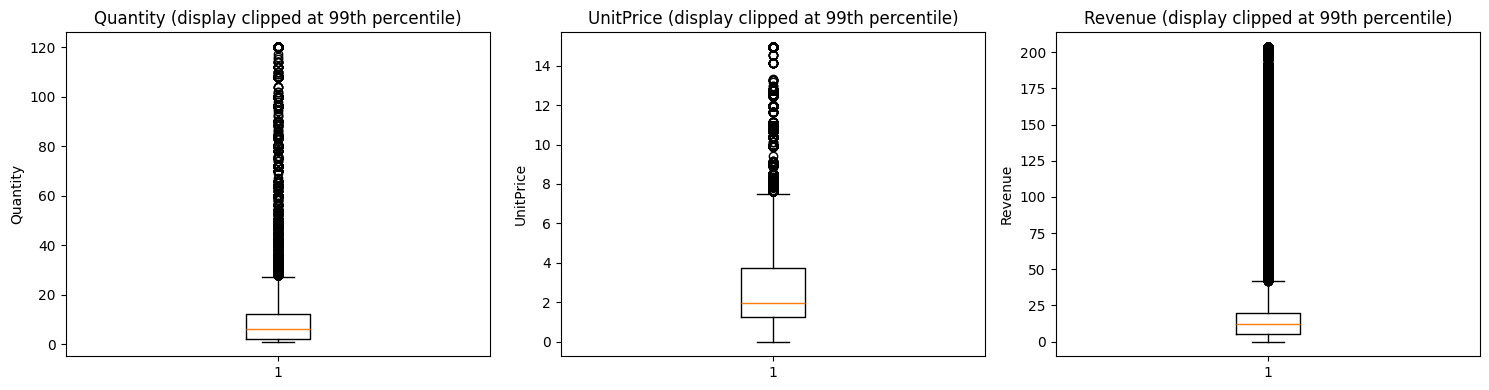

In [12]:
numeric_columns = ["Quantity", "UnitPrice", "Revenue"]
outlier_rows = []

for column in numeric_columns:
    series = transactions[column].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    upper_fence = q3 + 1.5 * iqr
    outlier_rows.append({
        "Feature": column,
        "Minimum": series.min(),
        "Median": series.median(),
        "99th Percentile": series.quantile(0.99),
        "Maximum": series.max(),
        "Values Above IQR Upper Fence": int((series > upper_fence).sum()),
    })

display(pd.DataFrame(outlier_rows).set_index("Feature"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, numeric_columns):
    upper = transactions[column].quantile(0.99)
    ax.boxplot(transactions[column].clip(upper=upper), vert=True)
    ax.set_title(f"{column} (display clipped at 99th percentile)")
    ax.set_ylabel(column)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "transaction_outlier_review.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Data Visualization and Exploratory Data Analysis

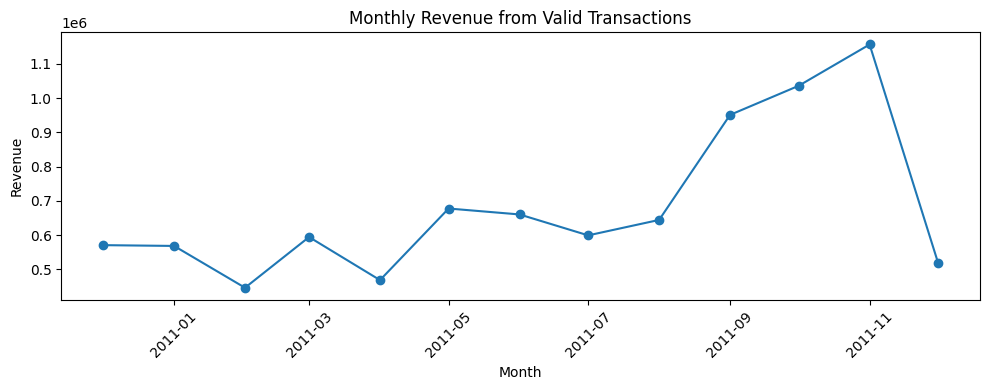

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


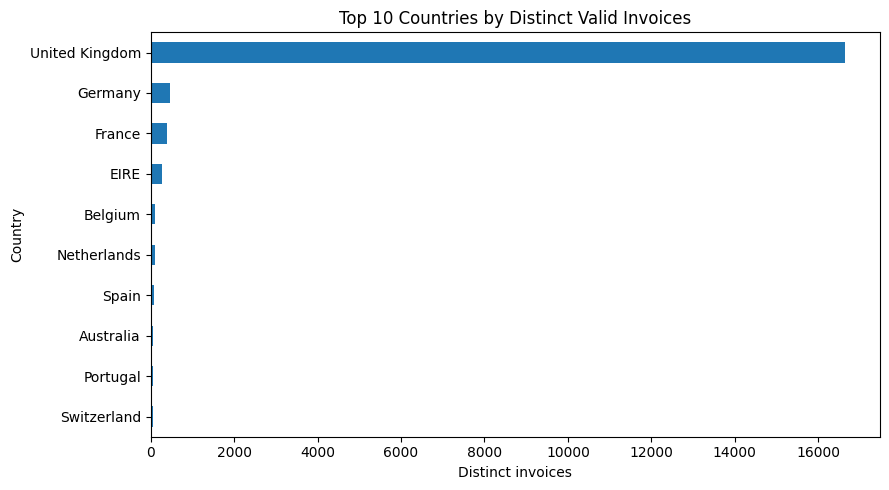

In [14]:
# Monthly revenue from valid transaction lines.
monthly_revenue = (
    transactions.assign(
        Month=transactions["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby("Month", as_index=False)["Revenue"].sum()
)

plt.figure(figsize=(10, 4))
plt.plot(monthly_revenue["Month"], monthly_revenue["Revenue"], marker="o")
plt.title("Monthly Revenue from Valid Transactions")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

top_countries = (
    transactions.groupby("Country")["InvoiceNo"].nunique()
    .sort_values(ascending=False).head(10).sort_values()
)
plt.figure(figsize=(9, 5))
top_countries.plot(kind="barh")
plt.title("Top 10 Countries by Distinct Valid Invoices")
plt.xlabel("Distinct invoices")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_countries_invoices.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Feature Engineering and Target Creation

### 8.0 Define the historical and target windows

In [15]:
HISTORY_DAYS = 90
TARGET_DAYS = 30

first_data_day = transactions['InvoiceDate'].min().normalize()
last_data_timestamp = transactions['InvoiceDate'].max()

# Find the first month-start that has at least 90 calendar days of prior dataset coverage.
first_possible = first_data_day + pd.Timedelta(days=HISTORY_DAYS)
first_snapshot = first_possible.to_period('M').to_timestamp()
if first_snapshot < first_possible:
    first_snapshot = first_snapshot + pd.offsets.MonthBegin(1)

# Keep only snapshots whose full 30-day target window ends by the last observed timestamp.
last_safe_snapshot_day = last_data_timestamp - pd.Timedelta(days=TARGET_DAYS)
snapshot_dates = pd.date_range(start=first_snapshot, end=last_safe_snapshot_day, freq='MS')

print('First eligible snapshot:', first_snapshot)
print('Last observed data timestamp:', last_data_timestamp)
print('Snapshot dates:', [d.strftime('%Y-%m-%d') for d in snapshot_dates])
if len(snapshot_dates) < 5:
    raise ValueError('Fewer than 5 monthly snapshots are available. Check the dataset date range and history/target windows.')


First eligible snapshot: 2011-03-01 00:00:00
Last observed data timestamp: 2011-12-09 12:50:00
Snapshot dates: ['2011-03-01', '2011-04-01', '2011-05-01', '2011-06-01', '2011-07-01', '2011-08-01', '2011-09-01', '2011-10-01', '2011-11-01']


In [16]:
feature_frames = []

for snapshot in snapshot_dates:
    history_start = snapshot - pd.Timedelta(days=HISTORY_DAYS)
    target_end = snapshot + pd.Timedelta(days=TARGET_DAYS)

    history = transactions.loc[
        (transactions['InvoiceDate'] >= history_start) &
        (transactions['InvoiceDate'] < snapshot)
    ]
    future = transactions.loc[
        (transactions['InvoiceDate'] >= snapshot) &
        (transactions['InvoiceDate'] < target_end)
    ]

    if history.empty:
        continue

    customer_features = history.groupby('CustomerID').agg(
        last_purchase_date=('InvoiceDate', 'max'),
        orders_last_90d=('InvoiceNo', 'nunique'),
        spend_last_90d=('Revenue', 'sum'),
        quantity_last_90d=('Quantity', 'sum'),
        unique_products_last_90d=('StockCode', 'nunique')
    ).reset_index()

    customer_features['recency_days'] = (
        snapshot - customer_features['last_purchase_date']
    ).dt.total_seconds() / (24 * 60 * 60)
    customer_features['avg_order_value_90d'] = (
        customer_features['spend_last_90d'] / customer_features['orders_last_90d'].clip(lower=1)
    )

    future_buyers = set(future['CustomerID'].unique())
    customer_features['target_purchase_next_30d'] = (
        customer_features['CustomerID'].isin(future_buyers).astype('int8')
    )
    customer_features['snapshot_date'] = snapshot
    customer_features = customer_features.drop(columns=['last_purchase_date'])
    feature_frames.append(customer_features)

if not feature_frames:
    raise ValueError('No customer snapshots were generated. Check the transaction dates and cleaning output.')

model_df = pd.concat(feature_frames, ignore_index=True)
model_df['CustomerID'] = model_df['CustomerID'].astype('int64')
model_df['snapshot_date'] = pd.to_datetime(model_df['snapshot_date'])

FEATURES = [
    'recency_days',
    'orders_last_90d',
    'spend_last_90d',
    'quantity_last_90d',
    'unique_products_last_90d',
    'avg_order_value_90d'
]
TARGET = 'target_purchase_next_30d'

print('Modeling dataset shape:', model_df.shape)
print('Unique customers across snapshots:', model_df['CustomerID'].nunique())
print('Snapshots:', model_df['snapshot_date'].nunique())
print('Overall positive-label rate:', f'{model_df[TARGET].mean():.1%}')
display(model_df.head())
display(model_df.groupby('snapshot_date')[TARGET].agg(['count', 'mean']).rename(columns={'count': 'eligible_customers', 'mean': 'purchase_rate'}))


Modeling dataset shape: (17837, 9)
Unique customers across snapshots: 3974
Snapshots: 9
Overall positive-label rate: 34.2%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CustomerID,orders_last_90d,spend_last_90d,quantity_last_90d,unique_products_last_90d,recency_days,avg_order_value_90d,target_purchase_next_30d,snapshot_date
0,12346,1,77183.60,74215,1,41.582639,77183.60,0,2011-03-01
1,12347,2,1187.18,634,49,33.395833,593.59,0,2011-03-01
2,12348,2,1120.24,1855,18,34.554167,560.12,0,2011-03-01
3,12350,1,334.40,197,17,26.332639,334.40,0,2011-03-01
4,12352,1,296.50,98,15,12.477083,296.50,1,2011-03-01


,eligible_customers,purchase_rate
snapshot_date,,
2011-03-01,1682,0.299049
2011-04-01,1776,0.278716
2011-05-01,1891,0.354310
2011-06-01,1959,0.324145
2011-07-01,1969,0.313357
2011-08-01,2025,0.317531
2011-09-01,1923,0.378575
2011-10-01,2151,0.352394
2011-11-01,2461,0.429094


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 8.1 Inspect purchase rate across snapshots and target-class balance


,snapshot_date,eligible_customers,purchase_rate
0,2011-03-01,1682,0.299049
1,2011-04-01,1776,0.278716
2,2011-05-01,1891,0.354310
3,2011-06-01,1959,0.324145
4,2011-07-01,1969,0.313357
5,2011-08-01,2025,0.317531
6,2011-09-01,1923,0.378575
7,2011-10-01,2151,0.352394
8,2011-11-01,2461,0.429094


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


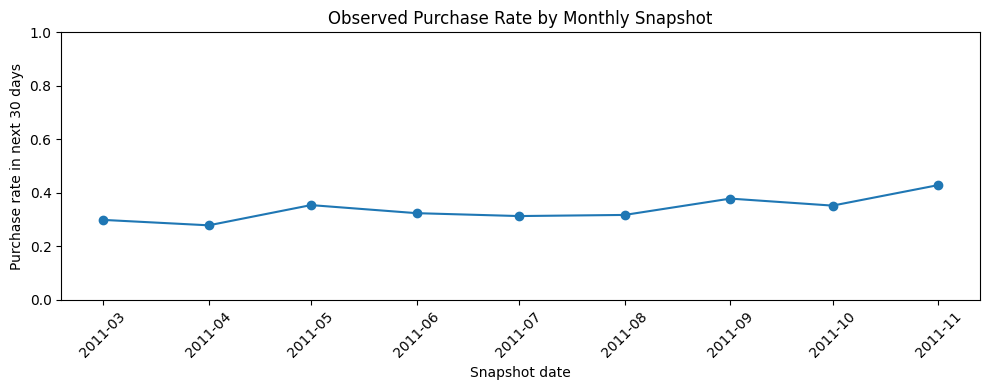

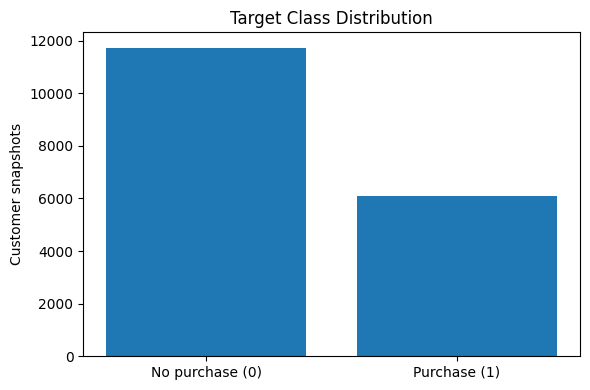

Target class percentages:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Percentage
target_purchase_next_30d,
0,65.77
1,34.23


In [17]:
snapshot_summary = (
    model_df.groupby("snapshot_date")[TARGET]
    .agg(eligible_customers="count", purchase_rate="mean")
    .reset_index()
)
display(snapshot_summary)

plt.figure(figsize=(10, 4))
plt.plot(snapshot_summary["snapshot_date"], snapshot_summary["purchase_rate"], marker="o")
plt.title("Observed Purchase Rate by Monthly Snapshot")
plt.xlabel("Snapshot date")
plt.ylabel("Purchase rate in next 30 days")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "purchase_rate_by_snapshot.png", dpi=150, bbox_inches="tight")
plt.show()

class_counts = model_df[TARGET].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(6, 4))
plt.bar(["No purchase (0)", "Purchase (1)"], class_counts.values)
plt.title("Target Class Distribution")
plt.ylabel("Customer snapshots")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "target_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Target class percentages:")
display((class_counts / class_counts.sum() * 100).round(2).rename("Percentage").to_frame())


### 8.2 Examine correlations between engineered features and the target

,recency_days,orders_last_90d,spend_last_90d,quantity_last_90d,unique_products_last_90d,avg_order_value_90d,target_purchase_next_30d
recency_days,1.00,-0.30,-0.14,-0.13,-0.23,-0.02,-0.13
orders_last_90d,-0.30,1.00,0.50,0.48,0.63,0.04,0.30
spend_last_90d,-0.14,0.50,1.00,0.89,0.37,0.53,0.15
quantity_last_90d,-0.13,0.48,0.89,1.00,0.38,0.60,0.15
unique_products_last_90d,-0.23,0.63,0.37,0.38,1.00,0.12,0.21
avg_order_value_90d,-0.02,0.04,0.53,0.60,0.12,1.00,0.03
target_purchase_next_30d,-0.13,0.30,0.15,0.15,0.21,0.03,1.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


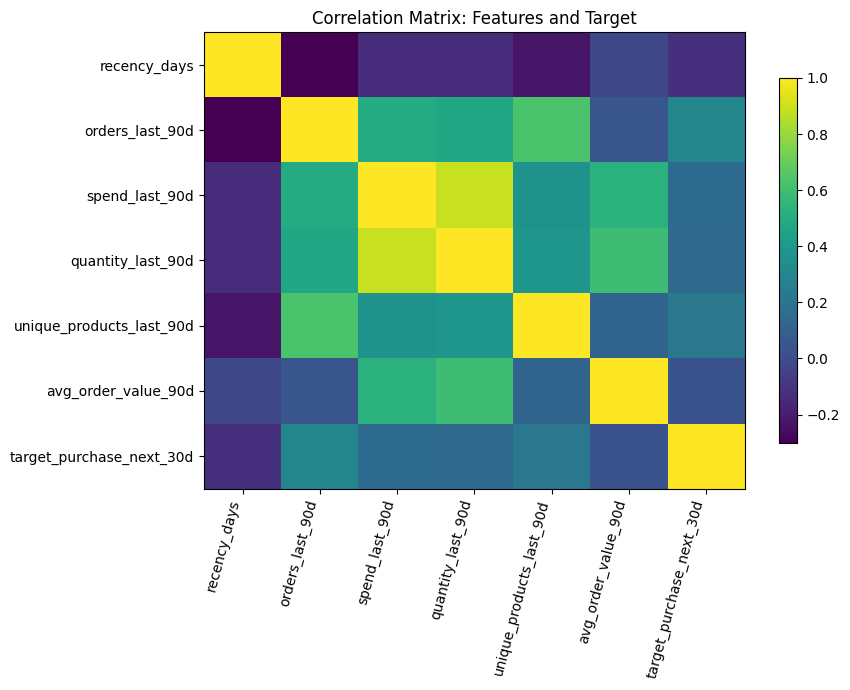

In [18]:
correlation_columns = FEATURES + [TARGET]
correlation_matrix = model_df[correlation_columns].corr(numeric_only=True)
display(correlation_matrix.round(2))

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation_matrix.values, aspect="auto")
ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))
ax.set_xticklabels(correlation_columns, rotation=75, ha="right")
ax.set_yticklabels(correlation_columns)
ax.set_title("Correlation Matrix: Features and Target")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_target_correlation.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Save Clean Data and Feature Dataset

In [19]:
clean_transactions_path = PROCESSED_DIR / 'clean_transactions.csv'
model_dataset_path = PROCESSED_DIR / 'customer_purchase_features.csv'
cleaning_report_path = REPORTS_DIR / 'cleaning_audit.csv'

transactions.to_csv(clean_transactions_path, index=False)
model_df.to_csv(model_dataset_path, index=False)
cleaning_summary.to_csv(cleaning_report_path, index=False)

print('Saved clean transactions to:', clean_transactions_path)
print('Saved modeling dataset to:', model_dataset_path)
print('Saved cleaning audit to:', cleaning_report_path)


Saved clean transactions to: /content/drive/MyDrive/customer_purchase_prediction/data/processed/clean_transactions.csv
Saved modeling dataset to: /content/drive/MyDrive/customer_purchase_prediction/data/processed/customer_purchase_features.csv
Saved cleaning audit to: /content/drive/MyDrive/customer_purchase_prediction/reports/cleaning_audit.csv


## 10. Chronological Split and Rolling Validation


In [20]:
unique_snapshots = sorted(pd.to_datetime(model_df["snapshot_date"].unique()))

if len(unique_snapshots) < 7:
    raise ValueError("Not enough snapshots for rolling validation and a two-snapshot test set.")

# Latest two complete snapshots are reserved for final testing.
test_dates = unique_snapshots[-2:]
development_dates = unique_snapshots[:-2]
test_df = model_df[model_df["snapshot_date"].isin(test_dates)].sort_values("snapshot_date").copy()
development_df = model_df[model_df["snapshot_date"].isin(development_dates)].sort_values("snapshot_date").copy()

print("Development snapshots:", [pd.Timestamp(d).strftime("%Y-%m-%d") for d in development_dates])
print("Final test snapshots:", [pd.Timestamp(d).strftime("%Y-%m-%d") for d in test_dates])
print(f"Development rows: {len(development_df):,}")
print(f"Final test rows: {len(test_df):,}")

X_test = test_df[FEATURES]
y_test = test_df[TARGET].astype(int)

if y_test.nunique() < 2:
    raise ValueError("The final test set must contain both target classes.")

# Use up to three expanding-window validation folds.
number_of_validation_folds = min(3, len(development_dates) - 4)
if number_of_validation_folds < 1:
    raise ValueError("Not enough development snapshots to run rolling validation.")
rolling_validation_dates = development_dates[-number_of_validation_folds:]

fold_overview = []
for validation_date in rolling_validation_dates:
    fold_train = development_df[development_df["snapshot_date"] < validation_date]
    fold_valid = development_df[development_df["snapshot_date"] == validation_date]
    fold_overview.append({
        "Training snapshot count": fold_train["snapshot_date"].nunique(),
        "Validation snapshot": pd.Timestamp(validation_date).strftime("%Y-%m-%d"),
        "Training rows": len(fold_train),
        "Validation rows": len(fold_valid),
        "Training purchase rate": fold_train[TARGET].mean(),
        "Validation purchase rate": fold_valid[TARGET].mean(),
    })

print("\nRolling validation folds:")
display(pd.DataFrame(fold_overview))


Development snapshots: ['2011-03-01', '2011-04-01', '2011-05-01', '2011-06-01', '2011-07-01', '2011-08-01', '2011-09-01']
Final test snapshots: ['2011-10-01', '2011-11-01']
Development rows: 13,225
Final test rows: 4,612

Rolling validation folds:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Training snapshot count,Validation snapshot,Training rows,Validation rows,Training purchase rate,Validation purchase rate
0,4,2011-07-01,7308,1969,0.315134,0.313357
1,5,2011-08-01,9277,2025,0.314757,0.317531
2,6,2011-09-01,11302,1923,0.315254,0.378575


## 11. Train and Compare Classification Models

In [21]:
candidate_models = {
    "Logistic Regression (log + scaled)": Pipeline([
        ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=0.5,
            max_iter=3000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=350,
        max_depth=14,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=350,
        max_depth=16,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        learning_rate=0.06,
        max_iter=200,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}

def positive_class_probability(estimator, X):
    class_labels = list(estimator.classes_)
    if 1 not in class_labels:
        raise ValueError("Model was not trained with positive class 1.")
    return estimator.predict_proba(X)[:, class_labels.index(1)]

def calculate_metrics(y_true, probabilities, threshold):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities, dtype=float)
    predictions = (probabilities >= threshold).astype(int)
    has_both_classes = np.unique(y_true).size == 2

    return {
        "accuracy": float(accuracy_score(y_true, predictions)),
        "precision": float(precision_score(y_true, predictions, zero_division=0)),
        "recall": float(recall_score(y_true, predictions, zero_division=0)),
        "f1": float(f1_score(y_true, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probabilities)) if has_both_classes else np.nan,
        "average_precision": float(average_precision_score(y_true, probabilities)) if has_both_classes else np.nan,
    }

def choose_f1_threshold(y_true, probabilities):
    thresholds = np.round(np.arange(0.10, 0.801, 0.025), 3)
    scores = [
        f1_score(y_true, (np.asarray(probabilities) >= threshold).astype(int), zero_division=0)
        for threshold in thresholds
    ]
    highest_score = max(scores)
    # If F1 ties, choose the higher threshold to avoid unnecessarily predicting positives.
    best_indices = [i for i, score in enumerate(scores) if np.isclose(score, highest_score)]
    best_index = best_indices[-1]
    return float(thresholds[best_index]), float(scores[best_index])

print("Candidate models:", list(candidate_models.keys()))


Candidate models: ['Logistic Regression (log + scaled)', 'Random Forest', 'Extra Trees', 'Histogram Gradient Boosting']


In [22]:
validation_model_results = []
validation_oof = {}
last_fold_models = {}
last_fold_validation_data = {}

# Majority-class baseline evaluated with rolling time-ordered folds.
baseline_y_all = []
baseline_probability_all = []

for validation_date in rolling_validation_dates:
    fold_train = development_df[development_df["snapshot_date"] < validation_date]
    fold_valid = development_df[development_df["snapshot_date"] == validation_date]

    X_fold_train, y_fold_train = fold_train[FEATURES], fold_train[TARGET].astype(int)
    X_fold_valid, y_fold_valid = fold_valid[FEATURES], fold_valid[TARGET].astype(int)

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_fold_train, y_fold_train)
    fold_probabilities = positive_class_probability(baseline, X_fold_valid)

    baseline_y_all.extend(y_fold_valid.tolist())
    baseline_probability_all.extend(fold_probabilities.tolist())

baseline_validation_metrics = calculate_metrics(
    baseline_y_all, baseline_probability_all, threshold=0.5
)
baseline_validation_row = {
    "model": "Majority-Class Baseline",
    "threshold": 0.5,
    **baseline_validation_metrics,
}

for model_name, estimator in candidate_models.items():
    oof_y = []
    oof_probabilities = []
    last_model = None
    last_X_valid = None
    last_y_valid = None

    for validation_date in rolling_validation_dates:
        fold_train = development_df[development_df["snapshot_date"] < validation_date]
        fold_valid = development_df[development_df["snapshot_date"] == validation_date]

        X_fold_train, y_fold_train = fold_train[FEATURES], fold_train[TARGET].astype(int)
        X_fold_valid, y_fold_valid = fold_valid[FEATURES], fold_valid[TARGET].astype(int)

        fold_model = clone(estimator)
        fold_model.fit(X_fold_train, y_fold_train)
        fold_probabilities = positive_class_probability(fold_model, X_fold_valid)

        oof_y.extend(y_fold_valid.tolist())
        oof_probabilities.extend(fold_probabilities.tolist())

        if validation_date == rolling_validation_dates[-1]:
            last_model = fold_model
            last_X_valid = X_fold_valid.copy()
            last_y_valid = y_fold_valid.copy()

    chosen_threshold, _ = choose_f1_threshold(oof_y, oof_probabilities)
    metrics = calculate_metrics(oof_y, oof_probabilities, threshold=chosen_threshold)

    validation_model_results.append({
        "model": model_name,
        "threshold": chosen_threshold,
        **metrics,
    })
    validation_oof[model_name] = {
        "y_true": np.asarray(oof_y),
        "probabilities": np.asarray(oof_probabilities),
    }
    last_fold_models[model_name] = last_model
    last_fold_validation_data[model_name] = (last_X_valid, last_y_valid)

candidate_validation_df = (
    pd.DataFrame(validation_model_results)
    .sort_values(["f1", "average_precision"], ascending=False)
    .reset_index(drop=True)
)
validation_results_df = pd.concat(
    [pd.DataFrame([baseline_validation_row]), candidate_validation_df],
    ignore_index=True,
)

print("Rolling validation model comparison:")
display(validation_results_df.round(4))

best_model_name = str(candidate_validation_df.iloc[0]["model"])
best_threshold = float(candidate_validation_df.iloc[0]["threshold"])

print("Selected model based on rolling validation F1:", best_model_name)
print("Selected threshold from rolling validation:", best_threshold)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: date

Rolling validation model comparison:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,Majority-Class Baseline,0.500,0.6640,0.0000,0.0000,0.000,0.5000,0.3360
1,Histogram Gradient Boosting,0.425,0.6273,0.4643,0.7088,0.561,0.7146,0.6046
2,Extra Trees,0.450,0.6427,0.4775,0.6740,0.559,0.7134,0.6097
3,Logistic Regression (log + scaled),0.475,0.6682,0.5051,0.6232,0.558,0.7171,0.6120
4,Random Forest,0.350,0.6022,0.4448,0.7414,0.556,0.7075,0.5997


Selected model based on rolling validation F1: Histogram Gradient Boosting
Selected threshold from rolling validation: 0.425


## 12. Final Model Training and Held-Out Test Evaluation

Final held-out test comparison:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,Majority-Class Baseline,0.500,0.6067,0.0000,0.0000,0.0000,0.5000,0.3933
1,Histogram Gradient Boosting,0.425,0.6119,0.5048,0.6918,0.5837,0.6865,0.6263



Classification report for selected model:
              precision    recall  f1-score   support

 No purchase       0.74      0.56      0.64      2798
    Purchase       0.50      0.69      0.58      1814

    accuracy                           0.61      4612
   macro avg       0.62      0.63      0.61      4612
weighted avg       0.65      0.61      0.62      4612



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


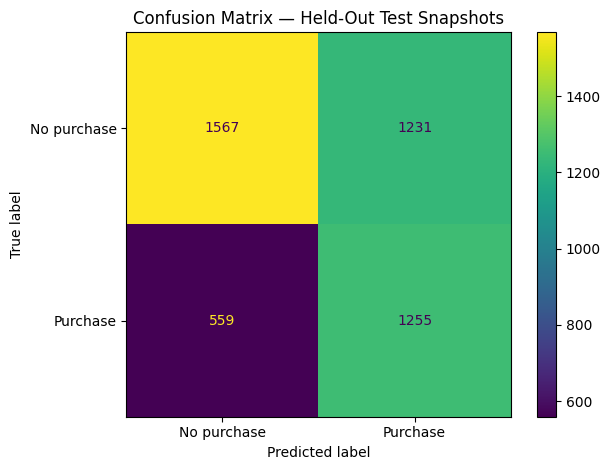

Test snapshots: ['2011-10-01', '2011-11-01']
Test rows: 4612
Actual purchase rate in test set: 39.33%


In [23]:
X_development = development_df[FEATURES]
y_development = development_df[TARGET].astype(int)

final_model = clone(candidate_models[best_model_name])
final_model.fit(X_development, y_development)

test_probabilities = positive_class_probability(final_model, X_test)
test_predictions_binary = (test_probabilities >= best_threshold).astype(int)
test_metrics = calculate_metrics(y_test, test_probabilities, threshold=best_threshold)

# Evaluate a majority-class baseline on the same held-out test rows.
test_baseline = DummyClassifier(strategy="most_frequent")
test_baseline.fit(X_development, y_development)
baseline_test_probabilities = positive_class_probability(test_baseline, X_test)
baseline_test_metrics = calculate_metrics(y_test, baseline_test_probabilities, threshold=0.5)

metrics_table = pd.DataFrame([
    {"model": "Majority-Class Baseline", "threshold": 0.5, **baseline_test_metrics},
    {"model": best_model_name, "threshold": best_threshold, **test_metrics},
])

print("Final held-out test comparison:")
display(metrics_table.round(4))

print("\nClassification report for selected model:")
print(classification_report(
    y_test,
    test_predictions_binary,
    labels=[0, 1],
    target_names=["No purchase", "Purchase"],
    zero_division=0,
))

cm = confusion_matrix(y_test, test_predictions_binary, labels=[0, 1])
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No purchase", "Purchase"],
)
cm_display.plot()
plt.title("Confusion Matrix — Held-Out Test Snapshots")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("Test snapshots:", [pd.Timestamp(d).strftime("%Y-%m-%d") for d in test_dates])
print("Test rows:", len(test_df))
print("Actual purchase rate in test set:", f"{y_test.mean():.2%}")


### 12.1 Precision–Recall and ROC curves

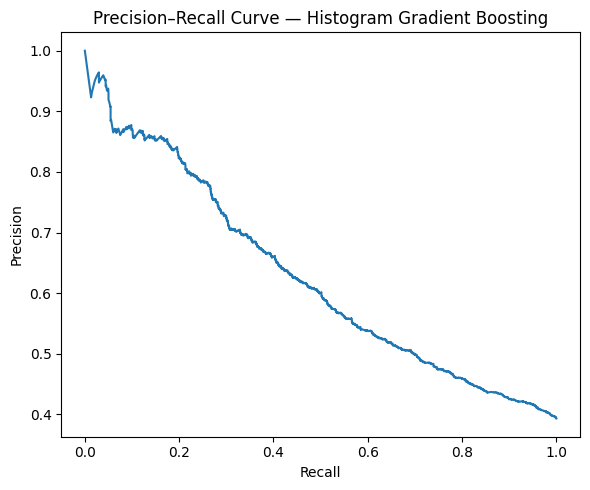

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


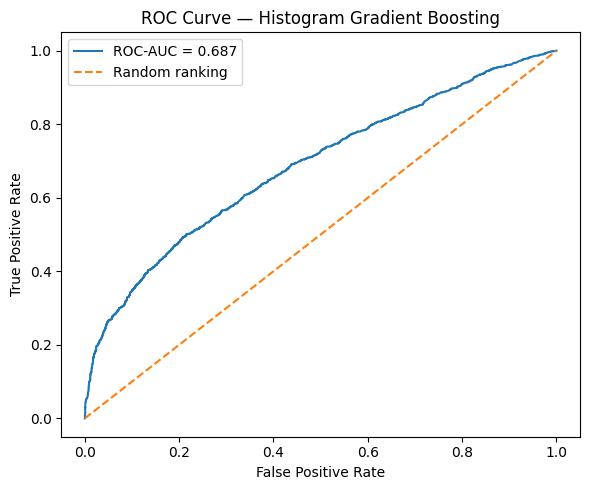

In [24]:
precision_values, recall_values, _ = precision_recall_curve(y_test, test_probabilities)
plt.figure(figsize=(6, 5))
plt.plot(recall_values, precision_values)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve — {best_model_name}")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_precision_recall_curve.png", dpi=150, bbox_inches="tight")
plt.show()

fpr, tpr, _ = roc_curve(y_test, test_probabilities)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {test_metrics['roc_auc']:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve — {best_model_name}")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()


## 13. Feature Selection and Importance

,feature,importance_mean,importance_std
1,orders_last_90d,0.2110,0.0097
2,spend_last_90d,0.0109,0.0030
3,quantity_last_90d,0.0086,0.0029
0,recency_days,0.0055,0.0025
5,avg_order_value_90d,0.0030,0.0022
4,unique_products_last_90d,0.0023,0.0030


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


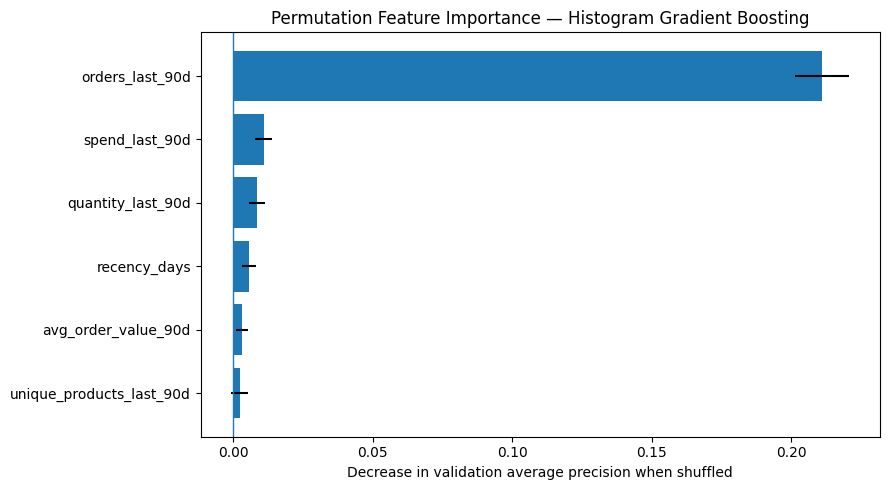

In [25]:
# Interpret features using the last rolling validation fold, not the held-out test set.
importance_model = last_fold_models[best_model_name]
X_importance, y_importance = last_fold_validation_data[best_model_name]

permutation_result = permutation_importance(
    importance_model,
    X_importance,
    y_importance,
    scoring="average_precision",
    n_repeats=8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": permutation_result.importances_mean,
    "importance_std": permutation_result.importances_std,
}).sort_values("importance_mean", ascending=True)

display(importance_df.sort_values("importance_mean", ascending=False).round(4))

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["feature"],
    importance_df["importance_mean"],
    xerr=importance_df["importance_std"],
)
plt.axvline(0, linewidth=1)
plt.title(f"Permutation Feature Importance — {best_model_name}")
plt.xlabel("Decrease in validation average precision when shuffled")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "permutation_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance_df.to_csv(REPORTS_DIR / "feature_importance.csv", index=False)


## 14. Save Prediction Results and Model Artifacts

In [26]:
MODEL_VERSION = datetime.now(timezone.utc).strftime("purchase-model-%Y%m%dT%H%M%SZ")

test_predictions_df = test_df[["CustomerID", "snapshot_date", TARGET]].copy()
test_predictions_df = test_predictions_df.rename(columns={
    "CustomerID": "customer_id",
    TARGET: "actual_purchase_next_30d",
})
test_predictions_df["purchase_probability"] = test_probabilities
test_predictions_df["predicted_purchase"] = test_predictions_binary
test_predictions_df["model_name"] = best_model_name
test_predictions_df["model_version"] = MODEL_VERSION

metrics_path = REPORTS_DIR / "test_metrics.csv"
validation_path = REPORTS_DIR / "validation_model_comparison.csv"
predictions_path = REPORTS_DIR / "test_predictions.csv"
model_path = MODELS_DIR / "purchase_prediction_model.joblib"

metrics_table.to_csv(metrics_path, index=False)
validation_results_df.to_csv(validation_path, index=False)
test_predictions_df.to_csv(predictions_path, index=False)

model_artifact = {
    "model": final_model,
    "model_name": best_model_name,
    "model_version": MODEL_VERSION,
    "features": FEATURES,
    "threshold": best_threshold,
    "history_days": HISTORY_DAYS,
    "target_days": TARGET_DAYS,
    "test_metrics": test_metrics,
    "validation_results": validation_results_df.to_dict(orient="records"),
}
joblib.dump(model_artifact, model_path)

print("Model version:", MODEL_VERSION)
print("Selected model:", best_model_name)
print("Selected threshold:", best_threshold)
print("Saved model artifact:", model_path)
print("Saved held-out test comparison:", metrics_path)
print("Saved rolling validation comparison:", validation_path)
print("Saved held-out test predictions:", predictions_path)
print("Saved feature importance:", REPORTS_DIR / "feature_importance.csv")
display(test_predictions_df.head())


Model version: purchase-model-20261022T221804Z
Selected model: Histogram Gradient Boosting
Selected threshold: 0.425
Saved model artifact: /content/drive/MyDrive/customer_purchase_prediction/models/purchase_prediction_model.joblib
Saved held-out test comparison: /content/drive/MyDrive/customer_purchase_prediction/reports/test_metrics.csv
Saved rolling validation comparison: /content/drive/MyDrive/customer_purchase_prediction/reports/validation_model_comparison.csv
Saved held-out test predictions: /content/drive/MyDrive/customer_purchase_prediction/reports/test_predictions.csv
Saved feature importance: /content/drive/MyDrive/customer_purchase_prediction/reports/feature_importance.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,customer_id,snapshot_date,actual_purchase_next_30d,purchase_probability,predicted_purchase,model_name,model_version
13225,12347,2011-10-01,0,0.481800,1,Histogram Gradient Boosting,purchase-model-20261022T221804Z
14667,16211,2011-10-01,0,0.385050,0,Histogram Gradient Boosting,purchase-model-20261022T221804Z
14666,16210,2011-10-01,1,0.599629,1,Histogram Gradient Boosting,purchase-model-20261022T221804Z
14665,16209,2011-10-01,0,0.490302,1,Histogram Gradient Boosting,purchase-model-20261022T221804Z
14664,16206,2011-10-01,1,0.257850,0,Histogram Gradient Boosting,purchase-model-20261022T221804Z


## 15. Demo: Predict for a Customer in the Latest Snapshot

In [27]:
latest_snapshot = pd.to_datetime(model_df["snapshot_date"].max())
latest_snapshot_df = model_df[model_df["snapshot_date"] == latest_snapshot].copy()

def predict_customer_purchase(
    customer_id,
    snapshot_frame=latest_snapshot_df,
    model=final_model,
    threshold=best_threshold,
):
    selected = snapshot_frame.loc[
        snapshot_frame["CustomerID"].astype(str) == str(customer_id)
    ]

    if selected.empty:
        raise ValueError(
            f"Customer {customer_id} is not eligible in snapshot {latest_snapshot.date()}."
        )

    probability = float(positive_class_probability(model, selected[FEATURES])[0])
    predicted = int(probability >= threshold)

    return {
        "customer_id": str(customer_id),
        "snapshot_date": str(pd.Timestamp(selected["snapshot_date"].iloc[0]).date()),
        "purchase_probability_next_30d": round(probability, 4),
        "predicted_purchase": predicted,
        "prediction_label": "Purchase predicted" if predicted else "No purchase predicted",
        "threshold": threshold,
        "model_name": best_model_name,
        "model_version": MODEL_VERSION,
    }

if not latest_snapshot_df.empty:
    demo_customer_id = str(latest_snapshot_df["CustomerID"].iloc[0])
    demo_result = predict_customer_purchase(demo_customer_id)
    print("Example historical prediction:")
    print(json.dumps(demo_result, indent=2))


Example historical prediction:
{
  "customer_id": "12347",
  "snapshot_date": "2011-11-01",
  "purchase_probability_next_30d": 0.3598,
  "predicted_purchase": 0,
  "prediction_label": "No purchase predicted",
  "threshold": 0.425,
  "model_name": "Histogram Gradient Boosting",
  "model_version": "purchase-model-20261022T221804Z"
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 16. Final Project Summary and Reproducibility Notes

### Deliverables created by this notebook
- `data/processed/clean_transactions.csv`
- `data/processed/customer_purchase_features.csv`
- `reports/cleaning_audit.csv`
- `reports/validation_model_comparison.csv`
- `reports/test_metrics.csv`
- `reports/test_predictions.csv`
- `reports/feature_importance.csv`
- `reports/figures/` with EDA and model-evaluation charts
- `models/purchase_prediction_model.joblib`

### Limitations
1. The dataset covers one historical year; it is not live transaction data.
2. The target represents observed purchasing under the defined 90-day history / 30-day target window. It does not guarantee future customer behaviour.
3. Testing is performed on later snapshots from the same historical retail dataset. It does not establish performance on new retailers or present-day shoppers.
4. Model and threshold selection use earlier rolling validation snapshots; the latest two snapshots are reserved for final testing.
5. Accuracy alone can be misleading when one class is more common. Review precision, recall, F1-score, ROC-AUC, average precision, and the majority baseline together.
6. Report the actual metrics from your run; do not promise or invent a target score.


### Interpreting the comparison
- The majority-class baseline is the reference point.
- The winning classifier is selected using rolling validation F1; average precision is used as a secondary comparison.
- The decision threshold is selected only from rolling validation predictions.
- The final test comparison shows whether the selected model actually improves on the baseline. If it does not, report that honestly and discuss plausible limitations rather than claiming an improvement that the measurements do not support.
